In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/marketing_clean.csv", parse_dates=["Dt_Customer"])
print(df.shape)

(2051, 33)


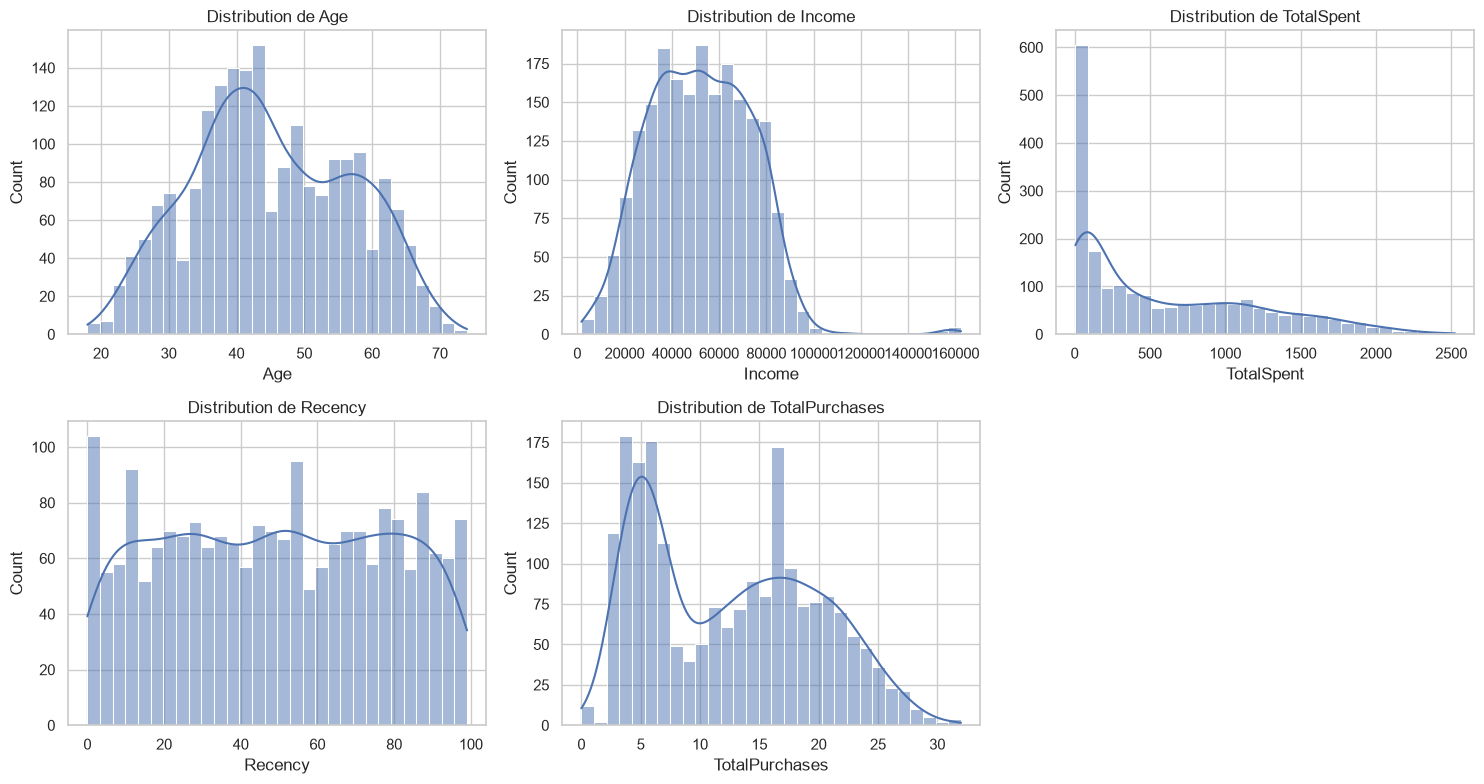

                    mean   median       std  skew
Age                45.13     44.0     11.67  0.09
Income          52054.20  51371.0  21473.93  0.37
TotalSpent        607.06    397.0    602.61  0.86
Recency            49.01     49.0     28.98 -0.00
TotalPurchases     12.55     12.0      7.19  0.29


In [2]:
num_cols = ["Age", "Income", "TotalSpent", "Recency", "TotalPurchases"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=ax)
    ax.set_title(f"Distribution de {col}")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

print(df[num_cols].agg(["mean", "median", "std", "skew"]).T.round(2))

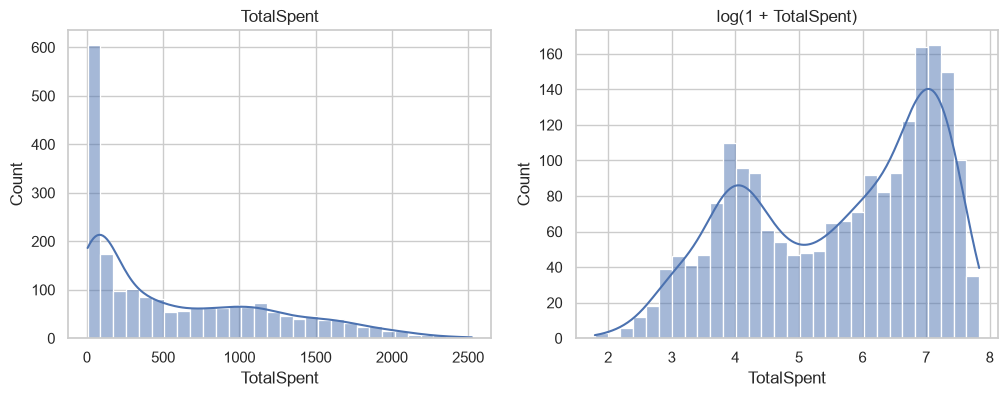

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["TotalSpent"], bins=30, kde=True, ax=ax[0])
ax[0].set_title("TotalSpent")
sns.histplot(np.log1p(df["TotalSpent"]), bins=30, kde=True, ax=ax[1])
ax[1].set_title("log(1 + TotalSpent)")
plt.show()

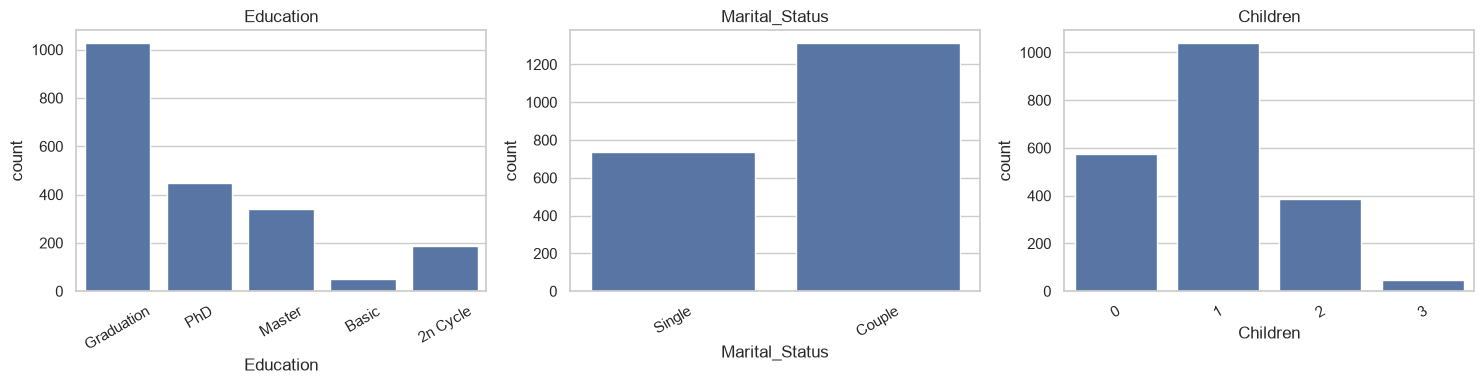

Education
Graduation    50.1
PhD           21.8
Master        16.6
2n Cycle       9.1
Basic          2.4
Name: proportion, dtype: float64


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Education", "Marital_Status", "Children"]):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

print(df["Education"].value_counts(normalize=True).round(3) * 100)

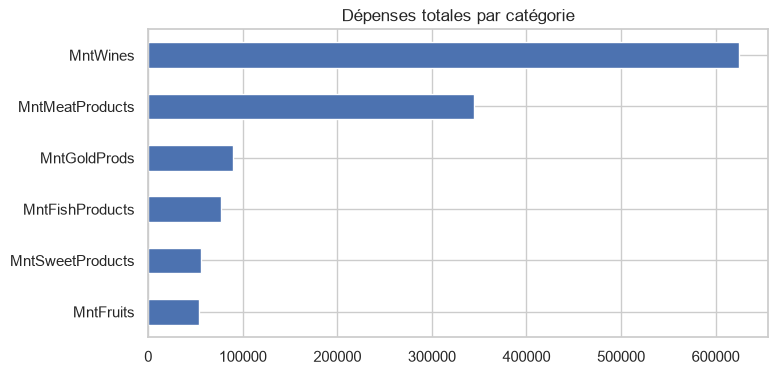

MntWines            50.1
MntMeatProducts     27.7
MntGoldProds         7.2
MntFishProducts      6.2
MntSweetProducts     4.5
MntFruits            4.3
dtype: float64


In [5]:
mnt_cols = [c for c in df.columns if c.startswith("Mnt")]

totaux = df[mnt_cols].sum().sort_values()
totaux.plot(kind="barh", figsize=(8, 4), title="Dépenses totales par catégorie")
plt.show()

print((totaux / totaux.sum() * 100).round(1).sort_values(ascending=False))

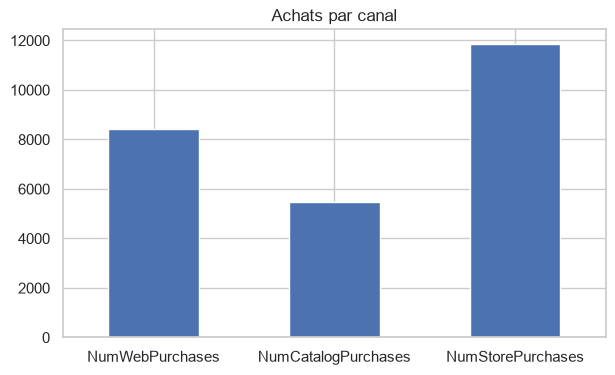

In [6]:
canaux = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]
df[canaux].sum().plot(kind="bar", figsize=(7, 4), title="Achats par canal")
plt.xticks(rotation=0)
plt.show()

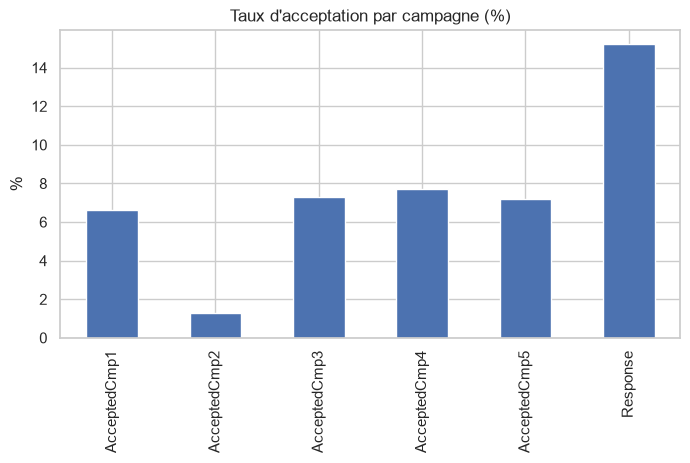

AcceptedCmp1     6.6
AcceptedCmp2     1.3
AcceptedCmp3     7.3
AcceptedCmp4     7.7
AcceptedCmp5     7.2
Response        15.2
dtype: float64


In [7]:
cmp_cols = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3",
            "AcceptedCmp4", "AcceptedCmp5", "Response"]

taux = (df[cmp_cols].mean() * 100).round(1)
taux.plot(kind="bar", figsize=(8, 4), title="Taux d'acceptation par campagne (%)")
plt.ylabel("%")
plt.show()
print(taux)

In [8]:
df["Year_Customer"] = df["Dt_Customer"].dt.year
print(df["Year_Customer"].value_counts().sort_index())

Year_Customer
2012     451
2013    1086
2014     514
Name: count, dtype: int64


## Conclusions de l'étape 2

- **Dépenses (TotalSpent)** : asymétrie modérée à droite (skew 0.86, moyenne 607 vs médiane 397), avec une forte concentration de clients à faibles dépenses.
- **Achats (TotalPurchases)** : distribution bimodale (pics autour de 5 et 17 achats), ce qui suggère deux profils : acheteurs occasionnels et réguliers.
- **Catégories** : les vins dominent largement les dépenses, suivis de la viande. Fruits, sucreries et poisson pèsent peu.
- **Canaux** : le magasin physique reste le premier canal (~46 % des achats), puis le web (~33 %) et le catalogue (~21 %).
- **Campagnes** : taux d'acceptation de 6,6 % à 7,7 % pour les campagnes 1, 3, 4 et 5, très faible pour la campagne 2 (~1,3 %). La dernière campagne (Response) atteint 15,2 %, soit environ le double.
- **Profil** : âge et revenu bien répartis, ancienneté concentrée sur 2012 à 2014 (surtout 2013).